In [10]:
import geopandas as gpd
from matplotlib import pyplot

In [11]:
# raw geojson filepaths

# POLLING_DISTRCITS = "../../data/raw/polling-districts.json"
POLLING_DISTRCITS = "../../data/leeds_polling_districts"
CYCLE_PATHS = "../../data/leeds_cycle_paths"

In [12]:
pd_gdf = gpd.read_file(POLLING_DISTRCITS)
pd_gdf.head()

,ID,WARD,POLLING_ST,AREA_HA,CONTACT,VERSION,LAST_AMEND,POLLING_DI,SHAPE_AREA,SHAPE_LEN,geometry
0,0,Kippax & Methley,Churchville House,451.437,Susanna Benton/Sue Wolfe - Electoral Registrat...,V 15.0 - 18/10/2020,NaN,KMA,4.514374e+06,9699.464089,"MULTIPOLYGON (((443250.697 435038.201, 443260...."
1,0,Garforth & Swillington,Garforth WMC,87.444,Susanna Benton/Sue Wolfe - Electoral Registrat...,V 15.0 - 18/10/2020,NaN,GSE,8.744380e+05,4870.920966,"POLYGON ((439337.238 432652.517, 439336.935 43..."
2,0,Headingley & Hyde Park,James Baillie Park,40.477,Susanna Benton/Sue Wolfe - Electoral Registrat...,V 15.0 - 18/10/2020,NaN,HHC,4.047709e+05,3636.182390,"POLYGON ((428594.481 435468.825, 428403.683 43..."
3,0,Alwoodley,Lord Darcy Public House,104.266,Susanna Benton/Sue Wolfe - Electoral Registrat...,V 15.0 - 18/10/2020,NaN,ALJ,1.042662e+06,5392.310145,"POLYGON ((430965.361 440099.459, 430965.138 44..."
4,0,Otley & Yeadon,Otley All Saints C of E Primary School,481.998,Susanna Benton/Sue Wolfe - Electoral Registrat...,V 15.0 - 18/10/2020,NaN,OYF,4.819975e+06,11051.532413,"POLYGON ((422053.036 443840.066, 422071.88 443..."


In [13]:
cp_gdf = gpd.read_file(CYCLE_PATHS)
cp_gdf.head()

,TYPE,CONTACT,VERSION,COLOR,SHAPE_Leng,geometry
0,bridleway,"Vicki Franks, Transport Policy Travelwise, Hig...",V 2.0 -13/11/2013,3,2306.714628,"LINESTRING (442143.787 427958.019, 442082.826 ..."
1,Local Network Proposals,"Vicki Franks, Transport Policy Travelwise, Hig...",V 2.0 -13/11/2013,230,439.815876,"LINESTRING (425789.566 433834.96, 425779.198 4..."
2,Main Radial Route proposed,"Vicki Franks, Transport Policy Travelwise, Hig...",V 2.0 -13/11/2013,131,81.063397,"LINESTRING (425526.653 434186.449, 425522.426 ..."
3,Main Radial Route proposed,"Vicki Franks, Transport Policy Travelwise, Hig...",V 2.0 -13/11/2013,131,78.224569,"LINESTRING (425593.651 434213.008, 425603.391 ..."
4,Local Network existing,"Vicki Franks, Transport Policy Travelwise, Hig...",V 2.0 -13/11/2013,11,467.083677,"LINESTRING (425656.032 434259.088, 425705.949 ..."


In [69]:
# can we find the polling districts with the most cycle lanes?

joined_gdf = pd_gdf.sjoin(
    cp_gdf,
    how="left",
    predicate="intersects",
    rsuffix="_cl"
)
cycle_wards_count = joined_gdf.groupby(by="WARD").size().reset_index().rename(columns={0: 'cycle_path_count'})

In [75]:
gdf = pd_gdf.merge(cycle_wards_count, on="WARD")
cycle_wards_df = gdf[["WARD", "geometry", "cycle_path_count"]]

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

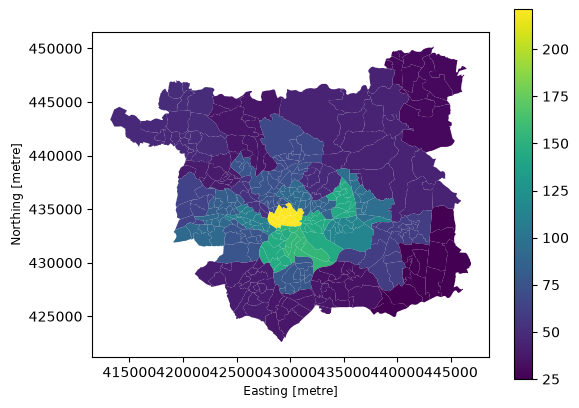

In [77]:
cycle_wards_df.plot(column="cycle_path_count", legend=True)